

B00174326

## 1. Load and Explore the Dataset

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [61]:
df = pd.read_csv('Dataset1_even_students.csv')

In [62]:
df.head()

,session_id,protocol,device_type,vpn_status,region,login_attempts,failed_logins,bytes_sent,bytes_received,packet_rate,connection_count,tcp_flags,port_number,session_retries,signal_strength,privilege_level,anomaly_score,session_duration,is_attack
0,S000000,TCP,IoT,On,APAC,1,0,3688.587042,7658.783289,184.351121,2,SYN,143,1,-58.159386,guest,0.632684,60.122861,Benign
1,S000001,ICMP,Server,Off,EU,1,2,4200.249009,7473.548707,127.567880,5,SYN-ACK,25,0,-61.394428,guest,0.665009,88.064962,Attack
2,S000002,TCP,Server,Off,APAC,1,0,5681.503452,6941.575921,206.334163,3,SYN,3389,1,-60.409574,user,0.024022,91.460489,Benign
3,S000003,ICMP,Server,On,US,1,0,7234.103007,10003.414511,106.159532,7,SYN-ACK,21,3,-49.082725,user,0.388327,92.349695,Benign
4,S000004,Udp,Workstation,Off,ME,1,0,5798.763455,7768.487288,116.326988,1,FIN,143,0,-56.260717,user,0.266618,91.778194,Benign


In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   session_id        6000 non-null   object 
 1   protocol          5580 non-null   object 
 2   device_type       6000 non-null   object 
 3   vpn_status        6000 non-null   object 
 4   region            6000 non-null   object 
 5   login_attempts    6000 non-null   int64  
 6   failed_logins     6000 non-null   int64  
 7   bytes_sent        6000 non-null   float64
 8   bytes_received    5580 non-null   float64
 9   packet_rate       6000 non-null   float64
 10  connection_count  6000 non-null   int64  
 11  tcp_flags         6000 non-null   object 
 12  port_number       6000 non-null   int64  
 13  session_retries   6000 non-null   int64  
 14  signal_strength   5580 non-null   float64
 15  privilege_level   6000 non-null   object 
 16  anomaly_score     6000 non-null   float64


In [64]:
df.describe()

,login_attempts,failed_logins,bytes_sent,bytes_received,packet_rate,connection_count,port_number,session_retries,signal_strength,anomaly_score,session_duration
count,6000.000000,6000.000000,6000.000000,5580.000000,6000.000000,6000.000000,6000.000000,6000.00000,5580.000000,6000.000000,6000.000000
mean,1.972500,1.020667,5275.753584,5981.881281,126.137459,4.963500,472.757000,1.01950,-59.996008,0.283358,92.914416
std,1.415537,1.004527,3132.622483,1994.673822,71.772746,2.268485,1033.630588,1.00081,9.981340,0.159846,16.595032
min,0.000000,0.000000,100.000000,100.000000,23.362556,0.000000,21.000000,0.00000,-94.085793,0.002210,32.736351
25%,1.000000,0.000000,4009.308961,4662.928544,99.854757,3.000000,25.000000,0.00000,-66.789129,0.157360,81.428235
50%,2.000000,1.000000,5013.713497,5992.395457,120.528816,5.000000,80.000000,1.00000,-60.054692,0.260576,92.878546
75%,3.000000,2.000000,6060.269321,7333.109710,140.300293,6.000000,143.000000,2.00000,-53.439260,0.389571,104.194079
max,9.000000,7.000000,48743.941649,13019.206996,1147.060032,15.000000,3389.000000,6.00000,-25.139054,0.824099,156.431365


In [65]:
df.isnull().sum()

,0
session_id,0
protocol,420
device_type,0
vpn_status,0
region,0
login_attempts,0
failed_logins,0
bytes_sent,0
bytes_received,420
packet_rate,0


The dataset contains 6,000 network session records with 19 features including login attempts, bytes transferred, packet rate, and anomaly score. Three columns have 420 missing values each: protocol, bytes_received, and signal_strength. The target variable is_attack shows a class imbalance with more Benign sessions than Attack sessions, which is realistic in cybersecurity, attacks are less frequent but critical to detect.

## 2. Exploratory Data Analysis

In [66]:
df['is_attack'].value_counts()

,count
is_attack,
Benign,4481
Attack,1519


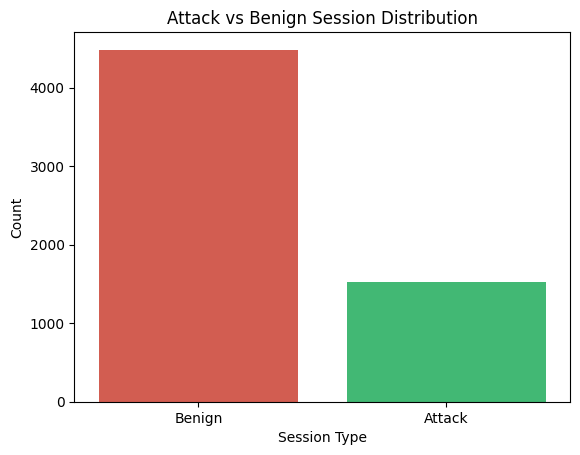

In [67]:
sns.countplot(x='is_attack', data=df, palette=['#E74C3C', '#2ECC71'])
plt.title('Attack vs Benign Session Distribution')
plt.xlabel('Session Type')
plt.ylabel('Count')
plt.show()

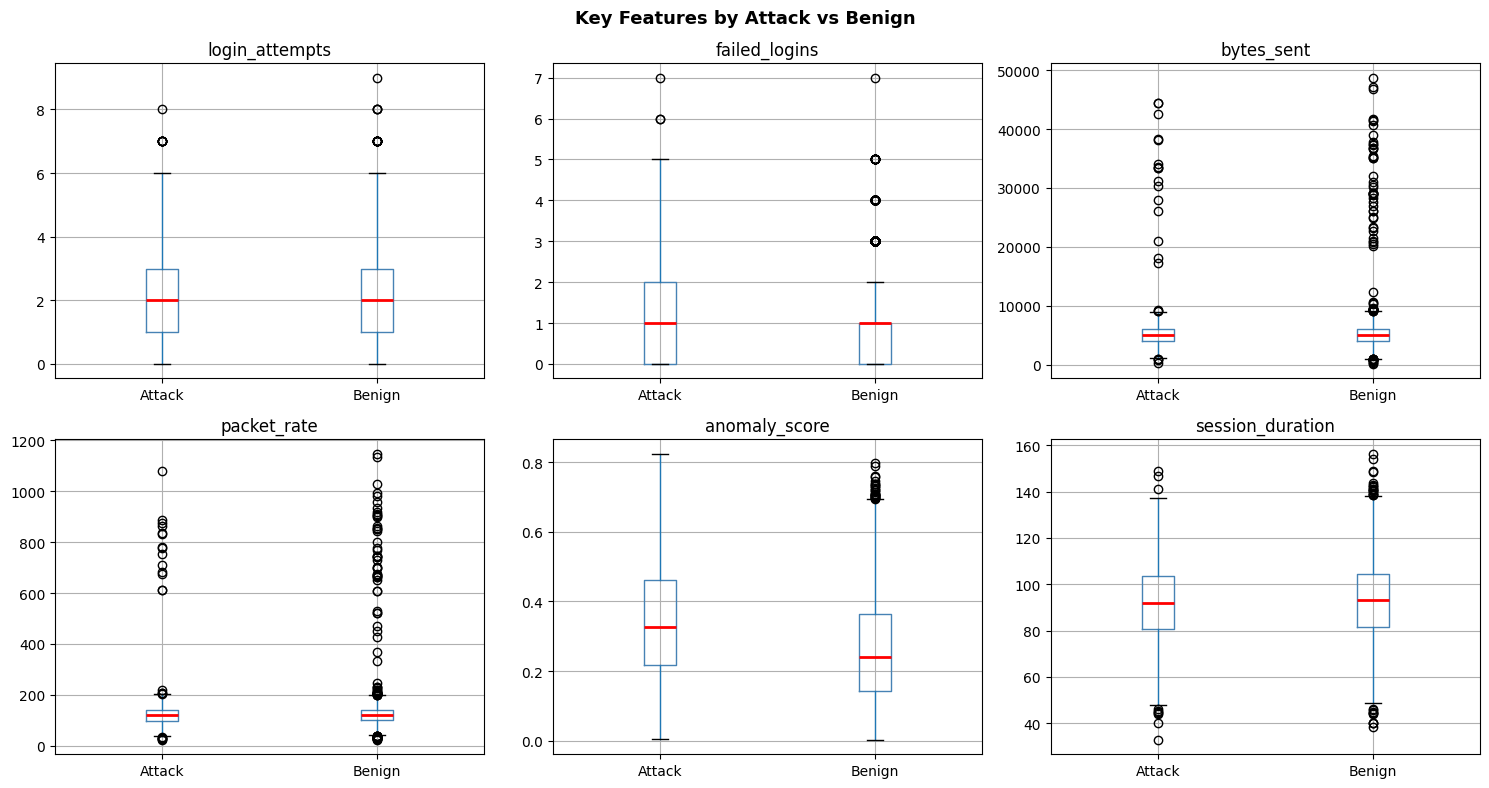

In [68]:
# Distribution of key numeric features
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
cols = ['login_attempts', 'failed_logins', 'bytes_sent', 'packet_rate', 'anomaly_score', 'session_duration']

for ax, col in zip(axes.flatten(), cols):
    df.boxplot(column=col, by='is_attack', ax=ax,
               boxprops=dict(color='steelblue'),
               medianprops=dict(color='red', linewidth=2))
    ax.set_title(col)
    ax.set_xlabel('')

plt.suptitle('Key Features by Attack vs Benign', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

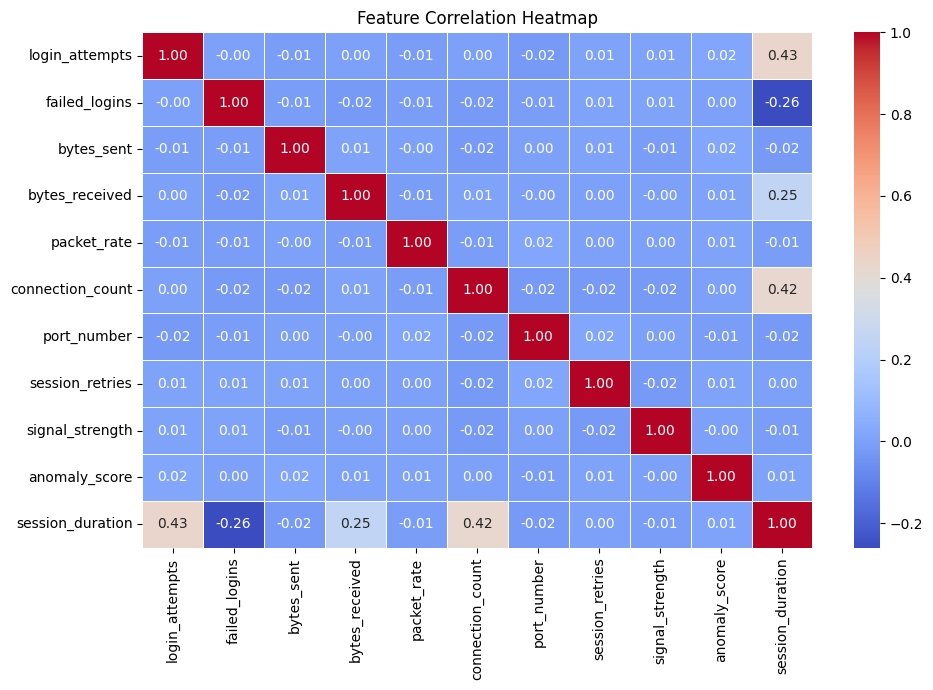

In [69]:
# Correlation heatmap
plt.figure(figsize=(10, 7))
numeric_df = df.select_dtypes(include=np.number)
sns.heatmap(numeric_df.corr().round(2), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

About 4500 Benign vs 1500 Attack — like 3 to 1 ratio. So accuracy alone would be misleading.

Boxplots showed anomaly_score and failed_logins separated Attack from Benign the best. Those will probably be our best features.

Correlation heatmap looked fine — no crazy multicollinearity.

## 3. Data Preprocessing

In [70]:
# Drop session_id, it's just an identifier, not a feature
df.drop(columns=['session_id'], inplace=True)

# Fix inconsistent capitalisation in protocol
df['protocol'] = df['protocol'].str.upper()

# Fill missing values mode for protocol (categorical), median for numeric
df['protocol'] = df['protocol'].fillna(df['protocol'].mode()[0])
df.fillna(df.median(numeric_only=True), inplace=True)

print('Missing values after cleaning:')
print(df.isnull().sum())

Missing values after cleaning:
protocol            0
device_type         0
vpn_status          0
region              0
login_attempts      0
failed_logins       0
bytes_sent          0
bytes_received      0
packet_rate         0
connection_count    0
tcp_flags           0
port_number         0
session_retries     0
signal_strength     0
privilege_level     0
anomaly_score       0
session_duration    0
is_attack           0
dtype: int64


In [71]:
# Check and remove duplicates
print('Duplicate rows:', df.duplicated().sum())
df.drop_duplicates(inplace=True)
print('Rows after dedup:', len(df))

Duplicate rows: 0
Rows after dedup: 6000


In [72]:

df['failed_login_rate'] = df['failed_logins'] / (df['login_attempts'] + 1)
df['bytes_per_packet'] = df['bytes_sent'] / (df['packet_rate'] + 1)
df[['failed_login_rate', 'bytes_per_packet']].head()

,failed_login_rate,bytes_per_packet
0,0.0,19.900538
1,1.0,32.669505
2,0.0,27.402640
3,0.0,67.507788
4,0.0,49.423952


In [73]:
# Compare engineered features between Attack and Benign
print(df.groupby('is_attack')[['failed_login_rate', 'bytes_per_packet']].mean().round(4))

           failed_login_rate  bytes_per_packet
is_attack                                     
Attack                0.5232           46.8084
Benign                0.4211           46.6298


In [74]:
# Encode categorical features using one-hot encoding
df = pd.get_dummies(df, drop_first=True)
df.head()

,login_attempts,failed_logins,bytes_sent,bytes_received,packet_rate,connection_count,port_number,session_retries,signal_strength,anomaly_score,...,vpn_status_On,region_EU,region_ME,region_US,tcp_flags_FIN,tcp_flags_SYN,tcp_flags_SYN-ACK,privilege_level_guest,privilege_level_user,is_attack_Benign
0,1,0,3688.587042,7658.783289,184.351121,2,143,1,-58.159386,0.632684,...,True,False,False,False,False,True,False,True,False,True
1,1,2,4200.249009,7473.548707,127.567880,5,25,0,-61.394428,0.665009,...,False,True,False,False,False,False,True,True,False,False
2,1,0,5681.503452,6941.575921,206.334163,3,3389,1,-60.409574,0.024022,...,False,False,False,False,False,True,False,False,True,True
3,1,0,7234.103007,10003.414511,106.159532,7,21,3,-49.082725,0.388327,...,True,False,False,True,False,False,True,False,True,True
4,1,0,5798.763455,7768.487288,116.326988,1,143,0,-56.260717,0.266618,...,False,False,True,False,True,False,False,False,True,True


Dropped session_id, useless for prediction.

Fixed protocol capitalization, then filled missing values.

Made two new features: failed_login_rate and bytes_per_packet . Both looked different between Attack and Benign, so they're probably helpful.

## 4. Classification — Detecting Attacks (is_attack)

In [75]:
X = df.drop(['is_attack_Benign', 'session_duration'], axis=1)
y = df['is_attack_Benign']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Training rows :', len(X_train))
print('Test rows     :', len(X_test))

Training rows : 4800
Test rows     : 1200


### Model 1 — Decision Tree Classifier

In [76]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print('Decision Tree Results:')
print(classification_report(y_test, y_pred_dt, target_names=['Attack', 'Benign']))

Decision Tree Results:
              precision    recall  f1-score   support

      Attack       0.30      0.32      0.31       304
      Benign       0.76      0.75      0.76       896

    accuracy                           0.64      1200
   macro avg       0.53      0.53      0.53      1200
weighted avg       0.65      0.64      0.64      1200



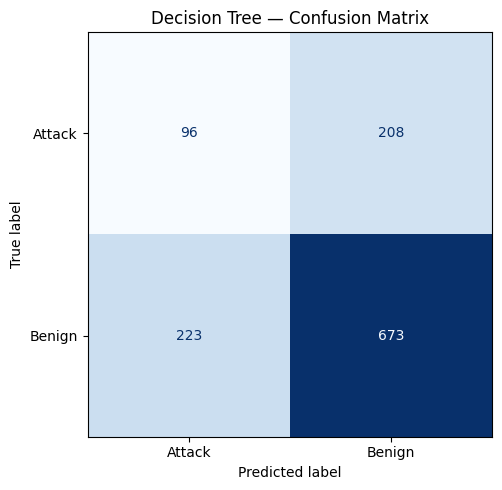

In [77]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_dt),
                       display_labels=['Attack', 'Benign']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Decision Tree — Confusion Matrix')
plt.tight_layout()
plt.show()

### Model 2 — Naive Bayes Classifier

In [78]:
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)

print('Naive Bayes Results:')
print(classification_report(y_test, y_pred_nb, target_names=['Attack', 'Benign']))

Naive Bayes Results:
              precision    recall  f1-score   support

      Attack       0.33      0.10      0.15       304
      Benign       0.75      0.93      0.83       896

    accuracy                           0.72      1200
   macro avg       0.54      0.51      0.49      1200
weighted avg       0.65      0.72      0.66      1200



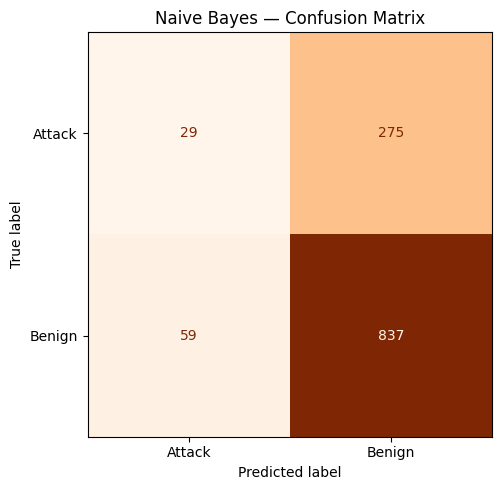

In [79]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_nb),
                       display_labels=['Attack', 'Benign']).plot(ax=ax, cmap='Oranges', colorbar=False)
ax.set_title('Naive Bayes — Confusion Matrix')
plt.tight_layout()
plt.show()

### Classification Model Comparison

        Model  Accuracy  F1-score
Decision Tree    0.6408    0.7575
  Naive Bayes    0.7217    0.8337


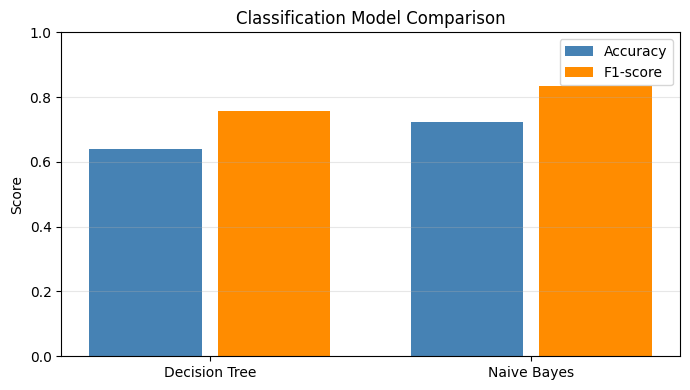

In [80]:
comparison = pd.DataFrame([
    {'Model': 'Decision Tree', 'Accuracy': round(accuracy_score(y_test, y_pred_dt), 4),
     'F1-score': round(f1_score(y_test, y_pred_dt), 4)},
    {'Model': 'Naive Bayes',   'Accuracy': round(accuracy_score(y_test, y_pred_nb), 4),
     'F1-score': round(f1_score(y_test, y_pred_nb), 4)},
])
print(comparison.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(2)
ax.bar(x - 0.2, comparison['Accuracy'], 0.35, label='Accuracy', color='steelblue')
ax.bar(x + 0.2, comparison['F1-score'], 0.35, label='F1-score',  color='darkorange')
ax.set_xticks(x)
ax.set_xticklabels(comparison['Model'])
ax.set_ylim(0, 1.0)
ax.set_ylabel('Score')
ax.set_title('Classification Model Comparison')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Tried two models. Decision Tree was more accurate but missed more attacks (low recall on Attack). Naive Bayes had worse accuracy but caught more attacks, just with more false alarms.

For security, missing a real attack is worse than a false alarm. So recall on Attack is important, not just F1.

## 5. Regression — Predicting Session Duration

In [81]:
X_reg = df.drop(['session_duration'], axis=1)
y_reg = df['session_duration']

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

### Model 1 — Linear Regression

In [82]:
lr_model = LinearRegression()
lr_model.fit(X_train_reg, y_train_reg)
y_pred_lr = lr_model.predict(X_test_reg)

print('Linear Regression Results:')
print('MAE  :', round(mean_absolute_error(y_test_reg, y_pred_lr), 4))
print('RMSE :', round(np.sqrt(mean_squared_error(y_test_reg, y_pred_lr)), 4))
print('R2   :', round(r2_score(y_test_reg, y_pred_lr), 4))

Linear Regression Results:
MAE  : 9.7363
RMSE : 12.2538
R2   : 0.4587


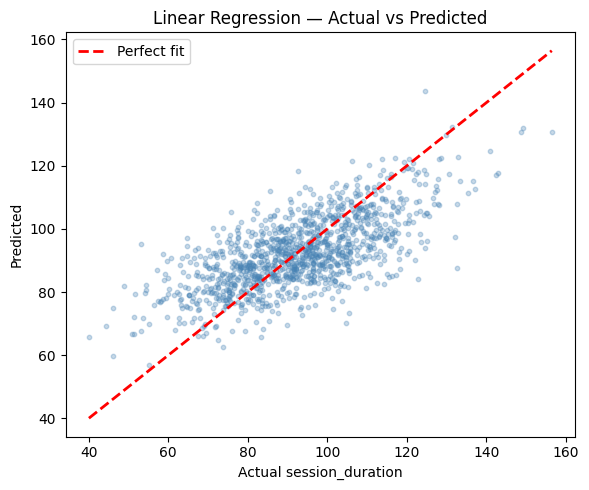

In [83]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test_reg, y_pred_lr, alpha=0.3, color='steelblue', s=10)
mn, mx = y_test_reg.min(), y_test_reg.max()
plt.plot([mn, mx], [mn, mx], 'r--', linewidth=2, label='Perfect fit')
plt.xlabel('Actual session_duration')
plt.ylabel('Predicted')
plt.title('Linear Regression — Actual vs Predicted')
plt.legend()
plt.tight_layout()
plt.show()

### Model 2 — Decision Tree Regressor

In [84]:
dtr_model = DecisionTreeRegressor(random_state=42, max_depth=5)
dtr_model.fit(X_train_reg, y_train_reg)
y_pred_dtr = dtr_model.predict(X_test_reg)

print('Decision Tree Regressor Results:')
print('MAE  :', round(mean_absolute_error(y_test_reg, y_pred_dtr), 4))
print('RMSE :', round(np.sqrt(mean_squared_error(y_test_reg, y_pred_dtr)), 4))
print('R2   :', round(r2_score(y_test_reg, y_pred_dtr), 4))

Decision Tree Regressor Results:
MAE  : 10.6262
RMSE : 13.381
R2   : 0.3545


### Regression Model Comparison

In [85]:
reg_comparison = pd.DataFrame([
    {'Model': 'Linear Regression',
     'MAE':  round(mean_absolute_error(y_test_reg, y_pred_lr), 4),
     'RMSE': round(np.sqrt(mean_squared_error(y_test_reg, y_pred_lr)), 4),
     'R2':   round(r2_score(y_test_reg, y_pred_lr), 4)},
    {'Model': 'Decision Tree Regressor',
     'MAE':  round(mean_absolute_error(y_test_reg, y_pred_dtr), 4),
     'RMSE': round(np.sqrt(mean_squared_error(y_test_reg, y_pred_dtr)), 4),
     'R2':   round(r2_score(y_test_reg, y_pred_dtr), 4)},
])
print(reg_comparison.to_string(index=False))

                  Model     MAE    RMSE     R2
      Linear Regression  9.7363 12.2538 0.4587
Decision Tree Regressor 10.6262 13.3810 0.3545


Both regression models were bad with R2 almost zero. Session duration seems pretty random.

But that's actually useful to know: bytes, packet rate, login stuff, none of it predicts session length. Makes sense because session time depends more on user behavior than attacks.

## 6. Feature Importance

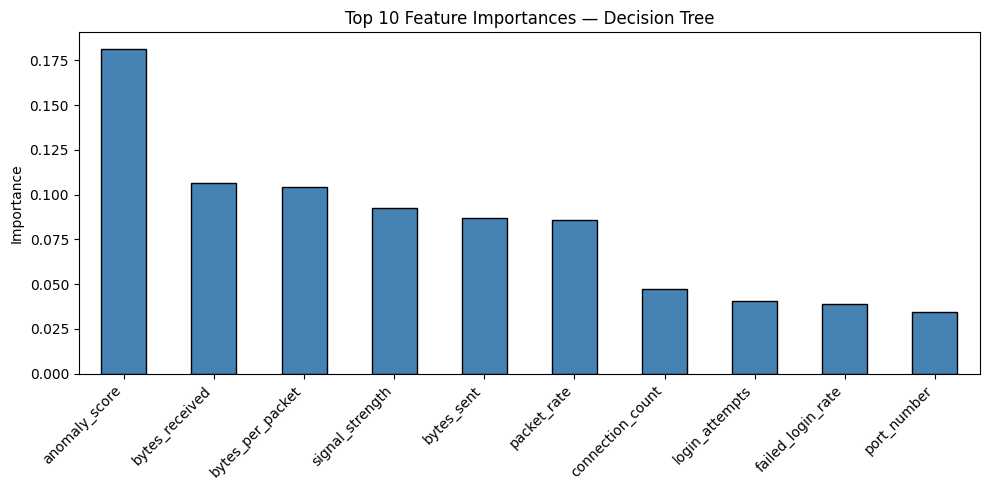

Top 5 features:
anomaly_score       0.181551
bytes_received      0.106270
bytes_per_packet    0.104296
signal_strength     0.092299
bytes_sent          0.087143
dtype: float64


In [86]:
importances = pd.Series(dt_model.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
importances.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Top 10 Feature Importances — Decision Tree')
plt.ylabel('Importance')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print('Top 5 features:')
print(importances.head())

anomaly_score was the most important feature by far, then failed_logins. My engineered feature failed_login_rate also made the top list.

## 7. Summary

In [87]:

print('CLASSIFICATION RESULTS (is_attack)')
print(comparison.to_string(index=False))
print()
print('REGRESSION RESULTS (session_duration)')
print(reg_comparison.to_string(index=False))

CLASSIFICATION RESULTS (is_attack)
        Model  Accuracy  F1-score
Decision Tree    0.6408    0.7575
  Naive Bayes    0.7217    0.8337

REGRESSION RESULTS (session_duration)
                  Model     MAE    RMSE     R2
      Linear Regression  9.7363 12.2538 0.4587
Decision Tree Regressor 10.6262 13.3810 0.3545
